## Imports

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # hide TensorFlow messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import arff
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, auc

from tensorflow import keras

keras.utils.set_random_seed(42)             # same results every run
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 35)


# Stage 1: Data Cleaning, Preparation and Exploration

### 1.1.0 Understanding and describing the dataset, features, target variable, and data types.

In [2]:
# Keep Training Dataset.arff in the same folder as this notebook.
data, meta = arff.loadarff("Training Dataset.arff")
df = pd.DataFrame(data)

# ARFF nominal values are loaded as byte strings. Convert them to integers.
for col in df.columns:
    df[col] = df[col].apply(lambda value: int(value.decode("utf-8")) if isinstance(value, bytes) else int(value))

print("Shape (rows, columns):", df.shape)
df.head()


Shape (rows, columns): (11055, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


In [3]:
target_col = "Result"
feature_cols = [col for col in df.columns if col != target_col]

print("Number of input features:", len(feature_cols))
print("Input features:")
print(feature_cols)
print()
print("Target column:", target_col)
print("Data types:")
print(df.dtypes.value_counts())


Number of input features: 30
Input features:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']

Target column: Result
Data types:
int64    31
Name: count, dtype: int64


Result
Phishing      4898
Legitimate    6157
Name: count, dtype: int64
Result
Phishing      44.3
Legitimate    55.7
Name: count, dtype: float64


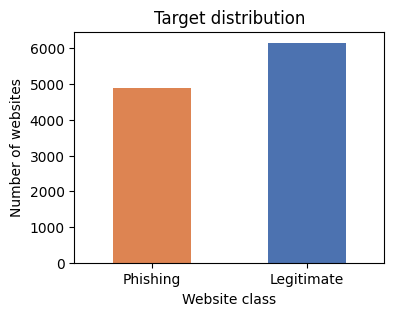

In [4]:
# Target meaning in this dataset:
# Result = -1: phishing website
# Result =  1: legitimate website
counts = df[target_col].value_counts().reindex([-1, 1], fill_value=0)
target_names = {-1: "Phishing", 1: "Legitimate"}

print(counts.rename(index=target_names))
print((counts / len(df) * 100).round(1).rename(index=target_names))

counts.rename(index=target_names).plot(kind="bar", color=["#DD8452", "#4C72B0"], figsize=(4, 3))
plt.title("Target distribution")
plt.xlabel("Website class")
plt.ylabel("Number of websites")
plt.xticks(rotation=0)
plt.show()


### 1.2.0 Identifying and handling Missing values

In [5]:
print("Empty cells (NaN):", df.isnull().sum().sum())

missing_count = df.isnull().sum()
missing_table = pd.DataFrame({
    "missing rows": missing_count,
    "percent": (missing_count / len(df) * 100).round(1)
})
missing_table[missing_table["missing rows"] > 0]


Empty cells (NaN): 0


,missing rows,percent


In [6]:
# Check whether missing values are concentrated in one target class.
if df.isnull().sum().sum() > 0:
    print(df.groupby(target_col).apply(lambda group: group.isnull().sum().sum()))
else:
    print("There are no missing values in the dataset.")


There are no missing values in the dataset.


### 1.2.1 Identifying and handling Duplicates and inconsistent data

In [7]:
print("Duplicated rows:", df.duplicated().sum())
print()

# The feature values in this dataset are encoded as -1, 0, or 1.
# Check that every feature contains only values allowed by its definition.
allowed_values = {-1, 0, 1}
invalid_counts = {
    col: int((~df[col].isin(allowed_values)).sum())
    for col in feature_cols
}
invalid_table = pd.Series(invalid_counts, name="invalid values")
print("Invalid values by feature:")
display(invalid_table[invalid_table > 0] if (invalid_table > 0).any() else invalid_table)
print()
print("Target values:", sorted(df[target_col].unique()))


Duplicated rows: 5206

Invalid values by feature:


,invalid values
having_IP_Address,0
URL_Length,0
Shortining_Service,0
having_At_Symbol,0
double_slash_redirecting,0
Prefix_Suffix,0
having_Sub_Domain,0
SSLfinal_State,0
Domain_registeration_length,0
Favicon,0



Target values: [np.int64(-1), np.int64(1)]


### 1.2.2 Identifying and handling Outliers

In [8]:
# These features use discrete codes (-1, 0, 1), not continuous measurements.
# Therefore, the usual IQR outlier rule is not meaningful here.
# Instead, inspect the frequency of each encoded value.
value_counts = pd.DataFrame({
    col: df[col].value_counts().reindex([-1, 0, 1], fill_value=0)
    for col in feature_cols
}).T
value_counts.columns = ["Value -1", "Value 0", "Value 1"]
value_counts.head(12)


,Value -1,Value 0,Value 1
having_IP_Address,3793,0,7262
URL_Length,8960,135,1960
Shortining_Service,1444,0,9611
having_At_Symbol,1655,0,9400
double_slash_redirecting,1429,0,9626
Prefix_Suffix,9590,0,1465
having_Sub_Domain,3363,3622,4070
SSLfinal_State,3557,1167,6331
Domain_registeration_length,7389,0,3666
Favicon,2053,0,9002


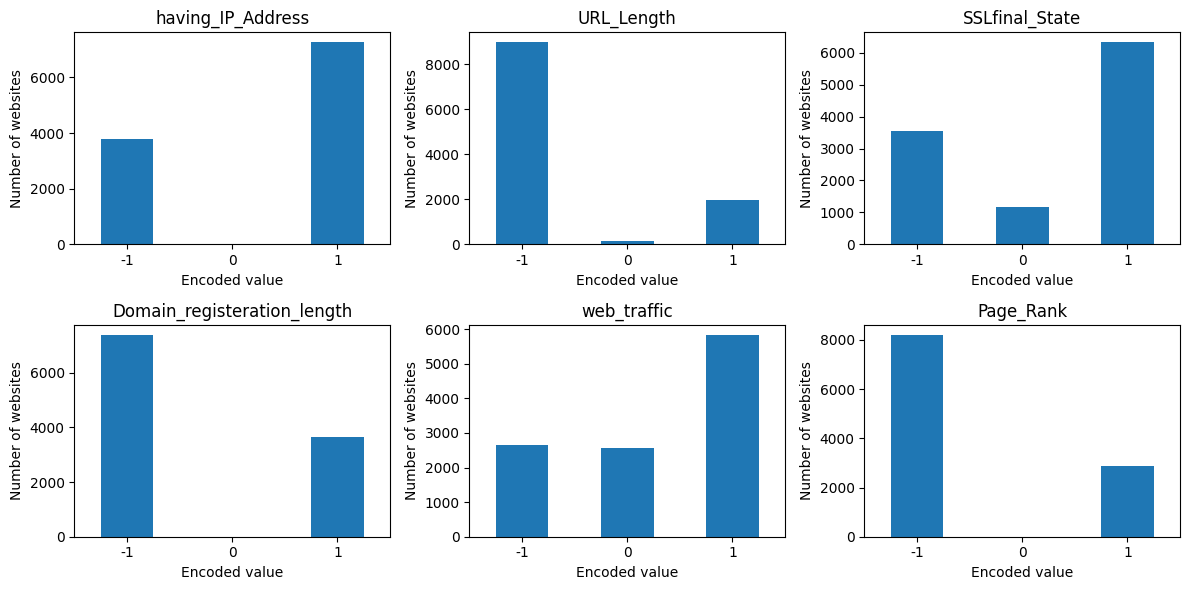

In [9]:
# Visualize the value distribution of selected phishing indicators.
selected_features = ["having_IP_Address", "URL_Length", "SSLfinal_State",
                     "Domain_registeration_length", "web_traffic", "Page_Rank"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), selected_features):
    df[col].value_counts().reindex([-1, 0, 1], fill_value=0).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Encoded value")
    ax.set_ylabel("Number of websites")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


### 1.3.0 Feature engineering

In [10]:
# Convert the original target into a binary target:
# 1 = Phishing, 0 = Legitimate.
y = (df[target_col] == -1).astype(int)

# Keep the 30 website features as model inputs.
# They are already numerically encoded, so no one-hot encoding is required.
X = df[feature_cols].copy()

print("Input features:", X.shape[1])
print("Phishing websites (1):", int(y.sum()))
print("Legitimate websites (0):", int((y == 0).sum()))


Input features: 30
Phishing websites (1): 4898
Legitimate websites (0): 6157


### 1.3.1 Feature preparation (already numerically encoded)

In [11]:
# The ARFF dataset represents feature values using -1, 0, and 1.
# These values are meaningful feature codes, so they can be used directly.
# No categorical one-hot encoding is necessary.
X_enc = X.copy()

print("Columns before preparation:", X.shape[1])
print("Columns after preparation:", X_enc.shape[1])
print("Missing feature values:", X_enc.isnull().sum().sum())
X_enc.head()


Columns before preparation: 30
Columns after preparation: 30
Missing feature values: 0


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1


### 1.4.0 Performing Exploratory Data Analysis (EDA)

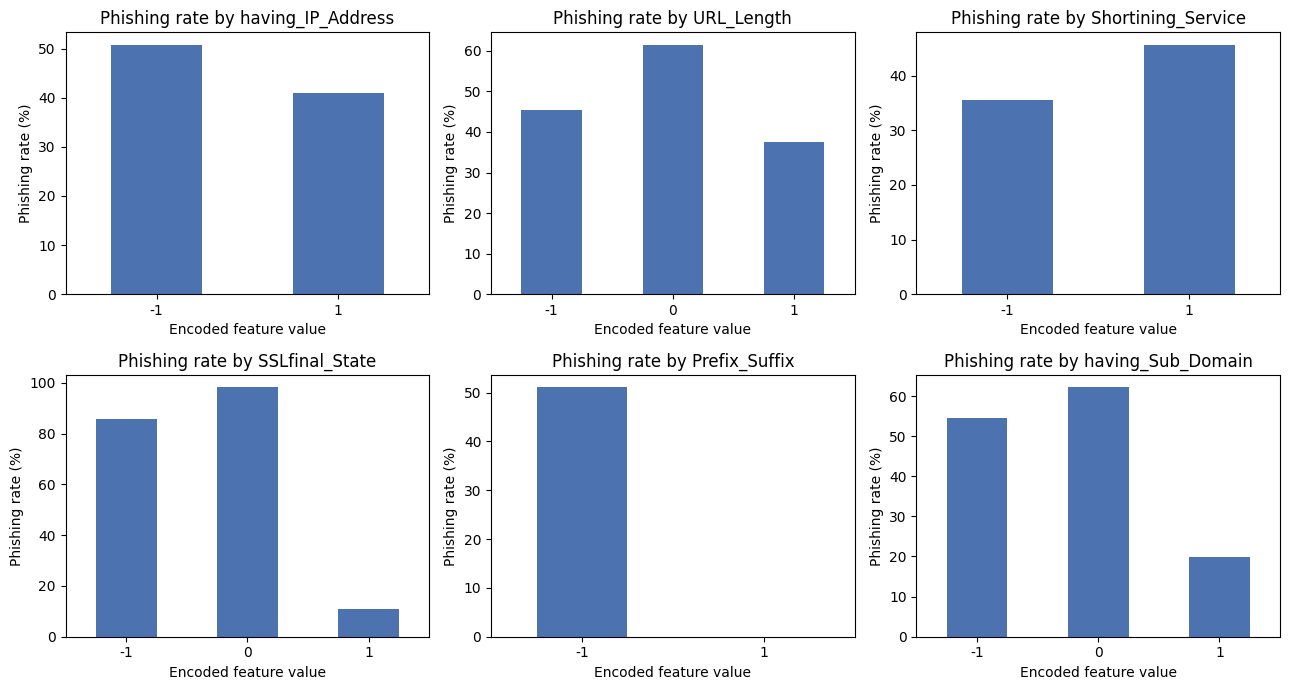

In [12]:
# Phishing rate (%) for selected feature values.
selected_features = ["having_IP_Address", "URL_Length", "Shortining_Service",
                     "SSLfinal_State", "Prefix_Suffix", "having_Sub_Domain"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), selected_features):
    phishing_rate = (df.groupby(col)[target_col].apply(lambda s: (s == -1).mean()) * 100)
    phishing_rate.reindex([-1, 0, 1]).dropna().plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title("Phishing rate by " + col)
    ax.set_xlabel("Encoded feature value")
    ax.set_ylabel("Phishing rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()


SSLfinal_State                -0.71
URL_of_Anchor                 -0.69
Prefix_Suffix                 -0.35
web_traffic                   -0.35
having_Sub_Domain             -0.30
Request_URL                   -0.25
Links_in_tags                 -0.25
SFH                           -0.22
Google_Index                  -0.13
age_of_domain                 -0.12
Page_Rank                     -0.10
having_IP_Address             -0.09
Statistical_report            -0.08
DNSRecord                     -0.08
URL_Length                    -0.06
having_At_Symbol              -0.05
on_mouseover                  -0.04
port                          -0.04
Links_pointing_to_page        -0.03
Submitting_to_email           -0.02
RightClick                    -0.01
popUpWidnow                   -0.00
Favicon                        0.00
Iframe                         0.00
Redirect                       0.02
double_slash_redirecting       0.04
HTTPS_token                    0.04
Abnormal_URL                

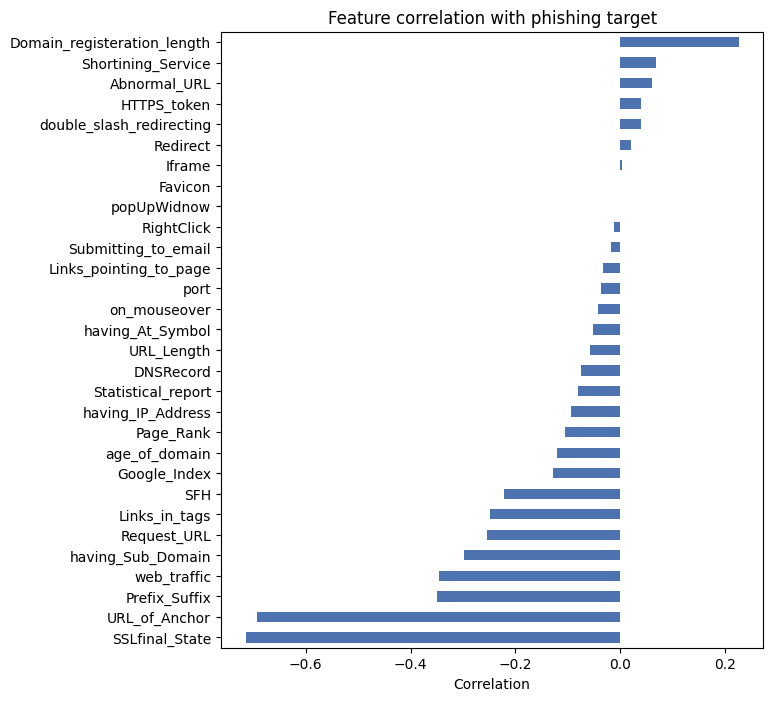

In [13]:
# Correlation of each feature with the binary phishing target.
corr = X_enc.corrwith(y).sort_values()

print(corr.round(2))
corr.plot(kind="barh", figsize=(7, 8), color="#4C72B0")
plt.title("Feature correlation with phishing target")
plt.xlabel("Correlation")
plt.show()
